<a href="https://colab.research.google.com/github/hizocar/machine_learning_egei/blob/main/docs/notebooks/s05_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 5 · Classification: Who Is Poor?

**Last session** we predicted (log) income per capita and learned to report an honest error with a
pipeline and cross-validation.

**Today's question.** A programme does not pay "a predicted income" — it decides *yes or no*: does this
household get the subsidy? So we predict the class directly: **is the household poor?**

**What is new today:** logistic regression as a predictor, the confusion matrix, precision and recall,
the decision threshold, the ROC curve and AUC, stratified splits — and how to put categorical variables
and missing values *inside* the pipeline (`OneHotEncoder`, `SimpleImputer`, `ColumnTransformer`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

DATA_URL = "https://raw.githubusercontent.com/hizocar/machine_learning_egei/main/docs/data/casen_households.csv"
LOCAL = Path("../data/casen_households.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)
df["poor"].value_counts(normalize=True).round(3)

poor
0    0.769
1    0.231
Name: proportion, dtype: float64

## 1. A stratified split, and the "nobody is poor" baseline

About 23% of households are poor. A random split could, by chance, put a different share in train and
test; `stratify=y` keeps the 23% in both. Then the first baseline: predict "not poor" for everybody.

In [2]:
NUM = ["head_age", "head_schooling_years", "household_size"]
HOURS = ["head_weekly_hours"]
CAT = ["region", "area", "head_sex", "head_activity", "head_job_type", "health_insurance",
       "head_nationality", "head_indigenous", "has_children", "has_elderly", "household_type",
       "housing_tenure", "dwelling_type", "overcrowding", "head_education"]

X = df[NUM + HOURS + CAT]
y = df["poor"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print(f"poor share  train {y_train.mean():.3f}   test {y_test.mean():.3f}")
print(f"Accuracy of 'nobody is poor': {1 - y_test.mean():.3f}")

poor share  train 0.231   test 0.231
Accuracy of 'nobody is poor': 0.769


A model that helps nobody is already **77% accurate**. Keep that number in mind.

## 2. Logistic regression — the model you know from econometrics, used to predict

In econometrics you used the logit to estimate effects. Here it is the same equation,
$P(\text{poor}) = 1 / (1 + e^{-(\beta_0 + \beta_1 x_1 + \dots)})$, but we judge it by how well it
predicts households it has never seen. Start with the three numeric variables from Session 4.

In [3]:
from sklearn.metrics import accuracy_score

num_model = make_pipeline(StandardScaler(), LogisticRegression())
num_model.fit(X_train[NUM].fillna(X_train[NUM].median()), y_train)
pred = num_model.predict(X_test[NUM].fillna(X_train[NUM].median()))
print(f"Accuracy, 3 numeric variables: {accuracy_score(y_test, pred):.3f}")

Accuracy, 3 numeric variables: 0.767


Barely different from the baseline. Accuracy cannot tell us *which* mistakes the model makes — and in
this problem the two mistakes have very different costs.

### ✋ The logit by hand, with one variable

The page fits $P(\text{poor})$ on years of schooling alone and computes three probabilities by hand.
Fit the same model and check your arithmetic.

In [4]:
one = df.dropna(subset=["head_schooling_years"]).sample(400, random_state=3)  # same 400 households as the page figure
logit1 = LogisticRegression().fit(one[["head_schooling_years"]], one["poor"])
b0, b1 = logit1.intercept_[0], logit1.coef_[0][0]
print(f"z = {b0:.3f} + ({b1:.3f}) × schooling")
for years in [8, 12, 16]:
    z = b0 + b1 * years
    print(f"{years:2d} years: z = {z:.3f}, p = 1/(1+e^-z) = {1 / (1 + np.exp(-z)):.3f}")
print(f"odds ratio per extra year: {np.exp(b1):.3f}")

z = -0.352 + (-0.086) × schooling
 8 years: z = -1.040, p = 1/(1+e^-z) = 0.261
12 years: z = -1.384, p = 1/(1+e^-z) = 0.200
16 years: z = -1.729, p = 1/(1+e^-z) = 0.151
odds ratio per extra year: 0.918


## 3. The confusion matrix: two different mistakes

| | predicted not poor | predicted poor |
|---|---|---|
| **actually not poor** | true negative | **false positive** — subsidy to a household that does not need it |
| **actually poor** | **false negative** — a poor household is left out | true positive |

- **Recall** = of the poor households, what share do we reach? TP / (TP + FN)
- **Precision** = of the households we select, what share are actually poor? TP / (TP + FP)

## 4. Use all the information: categorical variables and missing values in the pipeline

Most of what we know about a household is categorical (region, tenure, health insurance…). Models need
numbers, so `OneHotEncoder` turns each category into a 0/1 column. Missing values need a rule, and the
rule depends on what *missing* means:

| Column | Why it is missing | Rule |
|---|---|---|
| `head_weekly_hours` | the head does not work | fill with **0** — not the median! |
| `head_job_type` | the head does not work | its own category, `"missing"` |
| schooling, education, insurance, overcrowding | "doesn't know" (rare) | median / own category |

`ColumnTransformer` applies a different mini-pipeline to each group of columns. Everything that is
*learned* (medians, categories, scaling) is learned inside the pipeline — on training folds only.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ("hours", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), HOURS),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                          OneHotEncoder(handle_unknown="ignore")), CAT),
])
model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000))])
model.fit(X_train, y_train)
print(f"Accuracy, all variables: {accuracy_score(y_test, model.predict(X_test)):.3f}")

Accuracy, all variables: 0.797


precision 0.642   recall 0.269


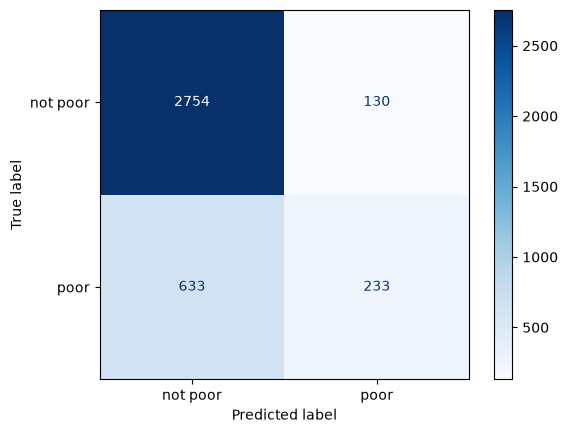

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score

pred = model.predict(X_test)                       # .predict() uses a 0.5 threshold
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["not poor", "poor"]).plot(cmap="Blues")
print(f"precision {precision_score(y_test, pred):.3f}   recall {recall_score(y_test, pred):.3f}")

79% accuracy — and the model **misses about three out of four poor households** (recall ≈ 0.26).
For a social programme, that is a failure that the accuracy number completely hides.

## 5. The threshold is a policy decision

`.predict()` says "poor" when the probability is above 0.5. Nothing says 0.5 is right. Lower the
threshold and we reach more poor households (recall ↑) at the price of subsidising more households
that are not poor (precision ↓).

In [7]:
p_test = model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    pr = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    rows.append({"threshold": t, "selected": tp + fp, "poor reached (TP)": tp, "poor missed (FN)": fn,
                 "non-poor subsidised (FP)": fp, "recall": tp / (tp + fn), "precision": tp / (tp + fp)})
pd.DataFrame(rows).round(3)

,threshold,selected,poor reached (TP),poor missed (FN),non-poor subsidised (FP),recall,precision
0,0.10,2570,802,64,1768,0.926,0.312
1,0.15,2109,750,116,1359,0.866,0.356
2,0.20,1700,684,182,1016,0.790,0.402
3,0.30,1066,528,338,538,0.610,0.495
4,0.40,633,367,499,266,0.424,0.580
5,0.50,363,233,633,130,0.269,0.642


Suppose leaving out a poor household is judged **three times as costly** as subsidising a household
that is not poor. Then we pick the threshold that minimises `3·FN + 1·FP`. (We do it on the test set here only to
see the idea; exercise 2 does it properly, with cross-validated predictions on the training set.)

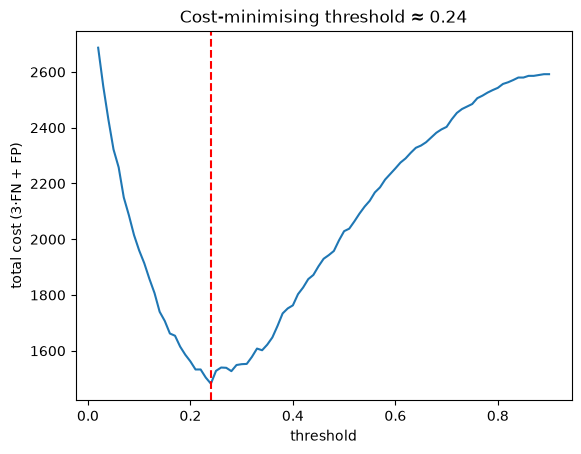

In [8]:
ts = np.linspace(0.02, 0.9, 89)
cost = [3 * ((p_test < t) & (y_test == 1)).sum() + ((p_test >= t) & (y_test == 0)).sum() for t in ts]
best = ts[int(np.argmin(cost))]
plt.plot(ts, cost); plt.axvline(best, ls="--", c="red")
plt.xlabel("threshold"); plt.ylabel("total cost (3·FN + FP)")
plt.title(f"Cost-minimising threshold ≈ {best:.2f}");

The cost ratio is not a statistical question. It is a value judgement that belongs to whoever runs
the programme — your job is to make the trade-off visible.

## 6. The ROC curve and AUC: the model across all thresholds

The ROC curve plots recall (true positive rate) against the false positive rate for every threshold.
The **AUC** summarises it: the probability that a random poor household gets a higher score than a
random non-poor one. 0.5 is a coin; 1.0 is perfect.

AUC: 0.794


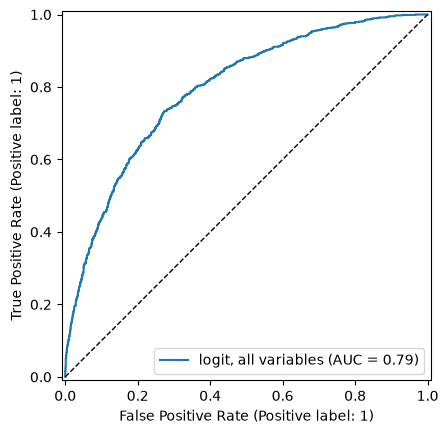

In [9]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

RocCurveDisplay.from_predictions(y_test, p_test, name="logit, all variables")
plt.plot([0, 1], [0, 1], "k--", lw=1)
print(f"AUC: {roc_auc_score(y_test, p_test):.3f}")

## 7. Honest evaluation: stratified cross-validation

Same idea as Session 4, with folds that each keep the 23% of poor households.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print("AUC per fold:", auc.round(3), f"  mean {auc.mean():.3f} ± {auc.std():.3f}")

AUC per fold: [0.775 0.785 0.785 0.766 0.793]   mean 0.781 ± 0.009


## 8. Leakage, again: what if we add income?

In [11]:
X_leak = df[NUM + HOURS + CAT + ["income_per_capita"]]
Xl_train, Xl_test = train_test_split(X_leak, test_size=0.25, stratify=y, random_state=42)
pre_leak = ColumnTransformer(pre.transformers + [("inc", StandardScaler(), ["income_per_capita"])])
leaky = Pipeline([("pre", pre_leak), ("clf", LogisticRegression(max_iter=3000))]).fit(Xl_train, y_train)
print(f"AUC with income: {roc_auc_score(y_test, leaky.predict_proba(Xl_test)[:, 1]):.3f}")

AUC with income: 0.965


Poverty is *defined* by comparing income per capita with a poverty line. Adding income makes the
model look excellent and makes it useless: the entire reason for a proxy means test is that income is
not reliably observed. Same lesson as `income_decile` last session.

## 9. Reading the model (carefully)

Exponentiated coefficients are odds ratios, as in econometrics. But this model was built to
*predict*: the coefficients describe associations among correlated variables, not causal effects.

In [12]:
names = model.named_steps["pre"].get_feature_names_out()
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names)
odds = np.exp(coef).sort_values()
pd.concat([odds.head(6), odds.tail(6)]).round(2).to_frame("odds ratio")

,odds ratio
cat__household_type_extended_two_parents,0.35
cat__head_education_6_tertiary_complete,0.40
cat__health_insurance_armed_forces,0.42
cat__health_insurance_isapre,0.50
cat__head_job_type_public_sector,0.51
cat__head_education_5_tertiary_incomplete,0.52
cat__head_education_0_none,1.65
cat__region_La Araucanía,1.69
cat__health_insurance_missing,1.88
cat__head_job_type_unpaid_family,1.89


## 10. With your assistant

```text
I have a logistic regression that predicts whether a household is poor (23% positive class).
Here is my confusion matrix at threshold 0.5: (paste). Explain in plain language what each cell means
for a social programme. Then write code that picks the threshold minimising 3*FN + 1*FP on
cross-validated predictions (not on the test set). Tell me why that last condition matters.
```
Check: did it use `cross_val_predict` (or equivalent) rather than the test set to choose the threshold?

## 11. Exercises

1. Recompute the cost-minimising threshold with a cost ratio of 1:1 and 5:1. How many more poor
   households are reached, and at what cost in false positives?
2. Choose the threshold using `cross_val_predict` on the training set, then report recall and precision
   on the test set once. Compare with the threshold chosen on the test set above — which is honest?
3. Drop `region`. Does the AUC change? Would a region-blind model be easier to defend politically?
4. Count the employed heads with missing `head_weekly_hours` (`df.query("head_activity == 'employed'")`).
   Why is 0 the wrong value for them? Propose a better rule, and say whether it must be learned from
   the training data — and therefore go inside the pipeline.